# Variational Autoencoder on a Ring of Gaussians

This notebook implements a **Variational Autoencoder (VAE)** from first principles in PyTorch on a two-dimensional mixture of Gaussians.

### Learning goals
1. Identify the encoder, decoder, prior, and approximate posterior.
2. Derive and implement the evidence lower bound (ELBO).
3. Explain the reparameterization trick.
4. Distinguish reconstruction from generation.
5. Diagnose a VAE through its latent space and generated samples.

The data and latent space are both 2D, so every important distribution can be visualized.

## Before you begin

**Prerequisites.** You should be comfortable with Gaussian distributions, expectations and KL divergence, basic neural networks, and PyTorch tensors/automatic differentiation. It helps to know why maximum likelihood is a useful training principle; no prior VAE implementation is assumed.

> **Notation and orientation**
> - $x\in\mathbb R^2$: observed ring point; $z\in\mathbb R^2$: latent code.
> - $q_\phi(z\mid x)$ is the encoder/approximate posterior; $p_\theta(x\mid z)$ is the decoder/likelihood; $p(z)=\mathcal N(0,I)$ is the prior.
> - **Inference/reconstruction:** $x\rightarrow z\rightarrow \hat x$. **Generation:** $z\sim p(z)\rightarrow x$; the encoder is not used.

## 1. Setup

Only NumPy, Matplotlib, and PyTorch are required. Training uses a GPU automatically when available.

**Runtime:** This toy model trains directly in the notebook. Expect roughly tens of seconds on a recent GPU and up to a few minutes on CPU. The exact time depends on your hardware.


In [1]:
import random
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (6, 5), "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.12.0+cu130 | device: cuda


## 2. Data: a ring of Gaussians

We sample from an equally weighted mixture of $K$ isotropic Gaussians:

$$\mu_k=r[\cos(2\pi k/K),\sin(2\pi k/K)]^\top,\qquad
x\mid k\sim\mathcal N(\mu_k,\sigma_{data}^2I).$$

The mode labels are retained only for plots. The VAE never sees them.

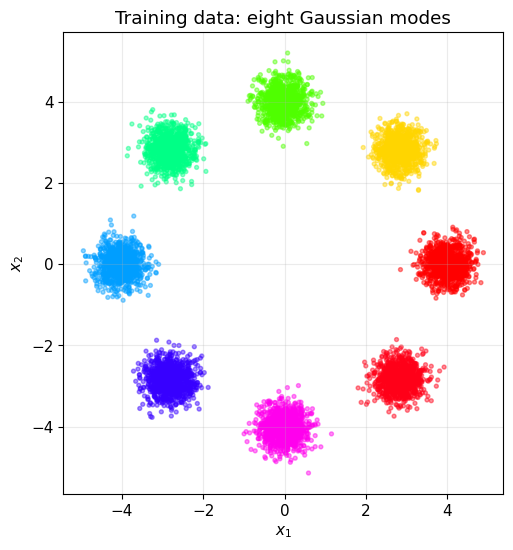

Train shape: (8000, 2)


In [2]:
def sample_ring(n_samples, n_modes=8, radius=4.0, std=0.30, seed=0):
    """Return observations and visualization-only component labels."""
    g = torch.Generator().manual_seed(seed)
    labels = torch.randint(n_modes, (n_samples,), generator=g)
    angles = 2 * torch.pi * labels.float() / n_modes
    centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
    return centers + std * torch.randn(n_samples, 2, generator=g), labels


N_MODES, RADIUS, DATA_STD = 8, 4.0, 0.30
x_train, y_train = sample_ring(8_000, N_MODES, RADIUS, DATA_STD, SEED)
x_test, y_test = sample_ring(2_000, N_MODES, RADIUS, DATA_STD, SEED + 1)
train_loader = DataLoader(
    TensorDataset(x_train),
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x_train[:, 0], x_train[:, 1], c=y_train, cmap="hsv", s=8, alpha=0.45)
ax.set(title="Training data: eight Gaussian modes", xlabel="$x_1$", ylabel="$x_2$")
ax.set_aspect("equal")
plt.show()
print("Train shape:", tuple(x_train.shape))

## 3. Model and reparameterization

The generative model and variational posterior are

$$p(z)=\mathcal N(0,I),\quad p_\theta(x\mid z)=\mathcal N(f_\theta(z),\sigma_x^2I),$$
$$q_\phi(z\mid x)=\mathcal N(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))).$$

The exact posterior is generally intractable. The encoder learns an approximation. To differentiate through a sample, isolate its randomness:

$$\epsilon\sim\mathcal N(0,I),\qquad z=\mu_\phi(x)+\sigma_\phi(x)\odot\epsilon.$$

This is the **reparameterization trick**.

In [3]:
class VAE(nn.Module):
    def __init__(self, x_dim=2, z_dim=2, hidden=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(x_dim, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh()
        )
        self.to_mu, self.to_logvar = nn.Linear(hidden, z_dim), nn.Linear(hidden, z_dim)
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, x_dim),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.to_mu(h), self.to_logvar(h).clamp(-10, 10)

    @staticmethod
    def reparameterize(mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar


model = VAE().to(DEVICE)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
  )
  (to_mu): Linear(in_features=64, out_features=2, bias=True)
  (to_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)
Parameters: 9,094


## 4. Evidence lower bound (ELBO)

$$\log p_\theta(x)\ge
\underbrace{\mathbb E_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]}_{\text{reconstruction}}
-\underbrace{D_{KL}(q_\phi(z\mid x)\|p(z))}_{\text{regularization}}.$$

For a diagonal Gaussian posterior,

$$D_{KL}=-\tfrac12\sum_j(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2).$$

With fixed decoder standard deviation $\sigma_x$, the reconstruction NLL (up to a constant) is $\|x-f_\theta(z)\|^2/(2\sigma_x^2)$. We minimize the negative ELBO and gradually warm the KL weight $\beta$ from 0 to 1.

In [4]:
DECODER_STD = 0.30


def vae_loss(x, reconstruction, mu, logvar, beta=1.0):
    recon_nll = ((x - reconstruction) ** 2).sum(1) / (2 * DECODER_STD**2)
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1)
    return (recon_nll + beta * kl).mean(), recon_nll.mean(), kl.mean()


# Shape and gradient test
example = x_train[:16].to(DEVICE)
reconstruction, mu, logvar = model(example)
loss, _, _ = vae_loss(example, reconstruction, mu, logvar)
loss.backward()
assert reconstruction.shape == example.shape
assert mu.shape == logvar.shape == (16, 2)
assert all(p.grad is not None for p in model.parameters())
model.zero_grad(set_to_none=True)
print(f"Sanity check passed | initial loss: {loss.item():.2f}")

Sanity check passed | initial loss: 88.87


## 5. Train

The reconstruction term promotes fidelity. On the other hand, the KL regularization term makes the latent representation compatible with the prior. Their tension is central to VAEs.

In [5]:
EPOCHS, WARMUP_EPOCHS = 500, 50  # 150, 30
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)  # 2e-3
history = {key: [] for key in ["loss", "reconstruction", "kl", "beta"]}
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    beta = min(1.0, epoch / WARMUP_EPOCHS)  # 1.0
    totals = np.zeros(3)
    for (batch,) in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        reconstruction, mu, logvar = model(batch)
        values = vae_loss(batch, reconstruction, mu, logvar, beta)
        values[0].backward()
        optimizer.step()
        totals += np.array([v.item() for v in values]) * len(batch)
    averages = totals / len(x_train)
    for key, value in zip(["loss", "reconstruction", "kl"], averages):
        history[key].append(value)
    history["beta"].append(beta)
    if epoch == 1 or epoch % 25 == 0:
        print(
            f"epoch {epoch:3d} | beta {beta:.2f} | loss {averages[0]:7.3f} | "
            f"recon {averages[1]:7.3f} | KL {averages[2]:6.3f}"
        )
print(f"Training time: {time.time() - start:.1f} s")

epoch   1 | beta 0.02 | loss  26.962 | recon  26.845 | KL  5.855
epoch  25 | beta 0.50 | loss   2.830 | recon   0.568 | KL  4.524
epoch  50 | beta 1.00 | loss   4.425 | recon   0.905 | KL  3.519
epoch  75 | beta 1.00 | loss   4.243 | recon   0.912 | KL  3.331
epoch 100 | beta 1.00 | loss   4.201 | recon   0.906 | KL  3.295
epoch 125 | beta 1.00 | loss   4.135 | recon   0.891 | KL  3.244
epoch 150 | beta 1.00 | loss   4.080 | recon   0.867 | KL  3.213
epoch 175 | beta 1.00 | loss   4.166 | recon   0.851 | KL  3.315
epoch 200 | beta 1.00 | loss   4.068 | recon   0.880 | KL  3.189
epoch 225 | beta 1.00 | loss   4.106 | recon   0.935 | KL  3.171
epoch 250 | beta 1.00 | loss   4.130 | recon   0.942 | KL  3.188
epoch 275 | beta 1.00 | loss   4.120 | recon   0.825 | KL  3.295
epoch 300 | beta 1.00 | loss   4.064 | recon   0.851 | KL  3.213
epoch 325 | beta 1.00 | loss   4.056 | recon   0.901 | KL  3.155
epoch 350 | beta 1.00 | loss   4.210 | recon   0.822 | KL  3.387
epoch 375 | beta 1.00 | l

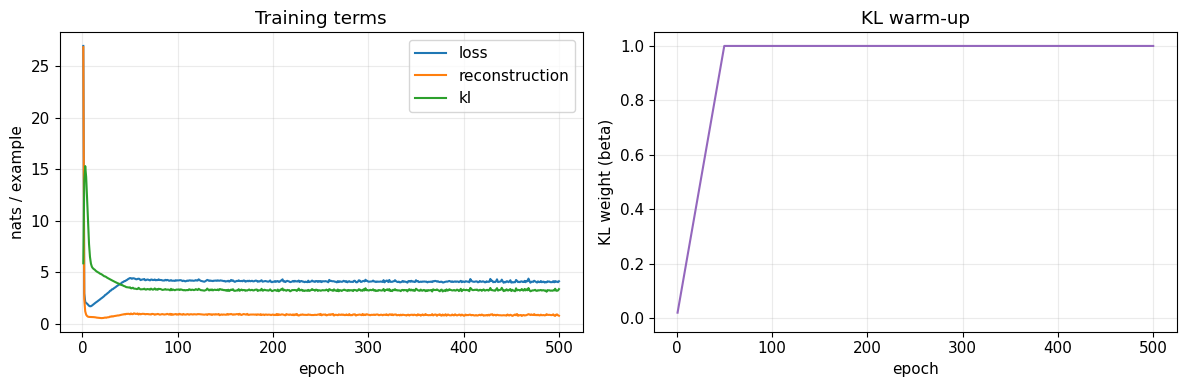

In [6]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key in ["loss", "reconstruction", "kl"]:
    axes[0].plot(epochs, history[key], label=key)
axes[0].set(xlabel="epoch", ylabel="nats / example", title="Training terms")
axes[0].legend()
axes[1].plot(epochs, history["beta"], color="tab:purple")
axes[1].set(
    xlabel="epoch", ylabel="KL weight (beta)", ylim=(-0.05, 1.05), title="KL warm-up"
)
plt.tight_layout()
plt.show()

## 6. Reconstructions and latent representation

We decode $\mu_\phi(x)$ for deterministic reconstructions. The colored latent plot approximates the **aggregated posterior** $q_\phi(z)=N^{-1}\sum_iq_\phi(z\mid x_i)$. Colors are held-out labels unseen during training.

> **Predict before running.** Will the encoded component clusters form an unregularized copy of the data ring, or rearrange to overlap the standard-normal prior? Also predict whether deterministic reconstructions will be sharper than prior samples. **Write one prediction and justify it from the two ELBO terms before running the cell.**

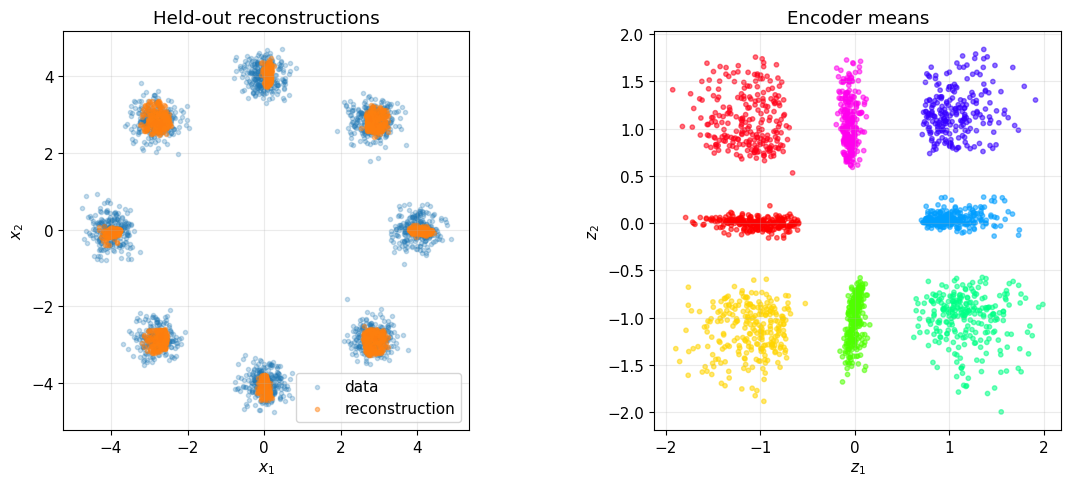

Reconstruction RMSE: 0.185
Mean posterior std: [0.226 0.202]


In [7]:
model.eval()
with torch.no_grad():
    z_mu, z_logvar = model.encode(x_test.to(DEVICE))
    reconstructed = model.decode(z_mu)
z_mu, z_logvar, reconstructed = z_mu.cpu(), z_logvar.cpu(), reconstructed.cpu()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(x_test[:, 0], x_test[:, 1], s=9, alpha=0.25, label="data")
axes[0].scatter(
    reconstructed[:, 0], reconstructed[:, 1], s=9, alpha=0.45, label="reconstruction"
)
axes[0].set(title="Held-out reconstructions", xlabel="$x_1$", ylabel="$x_2$")
axes[0].set_aspect("equal")
axes[0].legend()
axes[1].scatter(z_mu[:, 0], z_mu[:, 1], c=y_test, cmap="hsv", s=10, alpha=0.55)
axes[1].set(title="Encoder means", xlabel="$z_1$", ylabel="$z_2$")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.show()
print(f"Reconstruction RMSE: {torch.sqrt(((x_test-reconstructed)**2).mean()):.3f}")
print("Mean posterior std:", torch.exp(0.5 * z_logvar).mean(0).numpy().round(3))

> **Expected observation / interpretation.** Reconstructions can track the held-out points while the aggregated posterior is compressed and rearranged toward prior-supported regions. Good reconstruction alone therefore does not guarantee that arbitrary prior draws decode to data-like points. The KL term is what links those two uses of latent space.

## 7. Generate from the prior

Generation uses no encoder. We sample $z\sim\mathcal N(0,I)$, decode it, and optionally add likelihood noise $x\sim\mathcal N(f_\theta(z),\sigma_x^2I)$.

> **Predict before running.** Compared with reconstructions, where will samples from $z\sim\mathcal N(0,I)$ fall into? On all eight modes, between modes, or both? **Commit to an outcome and explain how prior–posterior mismatch and decoder continuity support it.**

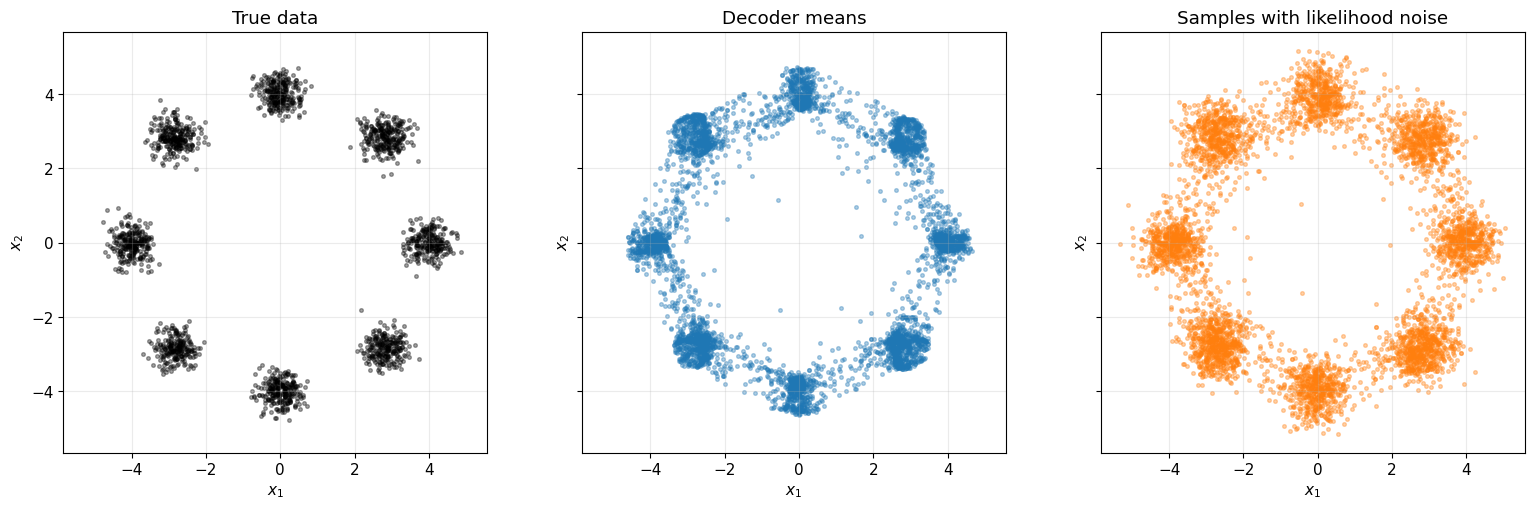

In [8]:
with torch.no_grad():
    prior_z = torch.randn(5_000, 2, device=DEVICE)
    generated_means = model.decode(prior_z)
    generated = generated_means + DECODER_STD * torch.randn_like(generated_means)
generated_means, generated = generated_means.cpu(), generated.cpu()

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
plots = [
    (x_test, "True data", PLOT_REFERENCE_COLOR),
    (generated_means, "Decoder means", "tab:blue"),
    (generated, "Samples with likelihood noise", PLOT_GENERATED_COLOR),
]
for ax, (points, title, color) in zip(axes, plots):
    ax.scatter(points[:, 0], points[:, 1], s=7, alpha=0.35, color=color)
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

> **Expected observation / interpretation.** Prior sampling can cover the ring while also producing some off-mode or connecting mass. The decoder is queried throughout prior-supported latent space, not only at codes produced by the encoder, so coverage and fidelity depend on how well the aggregated posterior matches the prior.

## 8. Decode a latent grid

The left panel shows where latent grid points lie under the prior. The right shows their decoded locations. A continuous decoder often creates **bridges between modes**. A connected latent region cannot map to perfectly separated components without sending some points through the gaps.

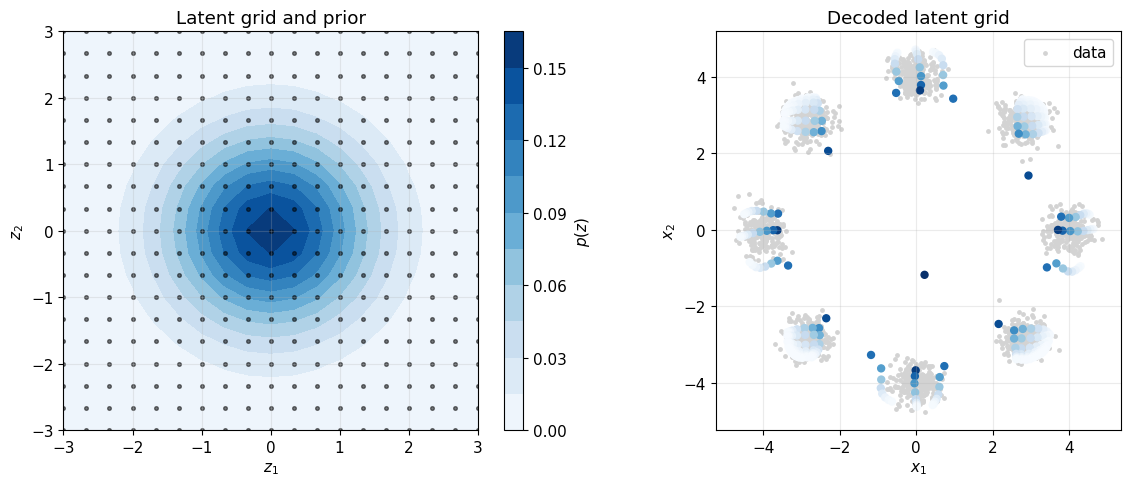

In [9]:
axis = torch.linspace(-3, 3, 19)
z1, z2 = torch.meshgrid(axis, axis, indexing="xy")
z_grid = torch.stack([z1.ravel(), z2.ravel()], 1)
with torch.no_grad():
    x_grid = model.decode(z_grid.to(DEVICE)).cpu()
density = torch.exp(-0.5 * (z1**2 + z2**2)) / (2 * torch.pi)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
contours = axes[0].contourf(z1, z2, density, levels=12, cmap="Blues")
axes[0].scatter(z_grid[:, 0], z_grid[:, 1], s=7, color=PLOT_REFERENCE_COLOR, alpha=0.5)
axes[0].set(title="Latent grid and prior", xlabel="$z_1$", ylabel="$z_2$")
fig.colorbar(contours, ax=axes[0], label="$p(z)$")
axes[1].scatter(x_test[:, 0], x_test[:, 1], s=6, color="lightgray", label="data")
axes[1].scatter(x_grid[:, 0], x_grid[:, 1], c=density.ravel(), cmap="Blues", s=25)
axes[1].set(title="Decoded latent grid", xlabel="$x_1$", ylabel="$x_2$")
axes[1].set_aspect("equal")
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Quantitative toy diagnostics

To later compare our VAE with other models, we measure radial error, nearest-mode frequencies, and the fraction of samples farther than three data standard deviations from every center. These are illustrative generative model metrics, no universal measures.

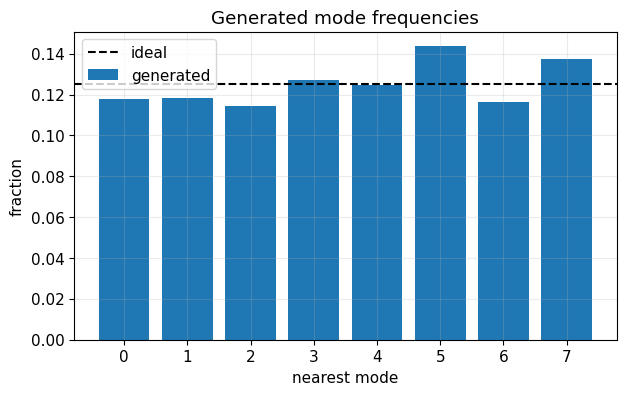

Mean absolute radial error: 0.366
Fraction >3σ from every mode: 18.5%
Modes receiving at least 1% of samples: 8/8


In [10]:
angles = 2 * torch.pi * torch.arange(N_MODES) / N_MODES
centers = RADIUS * torch.stack([torch.cos(angles), torch.sin(angles)], 1)
nearest_distance, nearest_mode = torch.cdist(generated, centers).min(1)
frequencies = torch.bincount(nearest_mode, minlength=N_MODES) / len(generated)
radial_error = (generated.norm(dim=1) - RADIUS).abs().mean()
gap_rate = (nearest_distance > 3 * DATA_STD).float().mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(N_MODES), frequencies.numpy(), label="generated")
ax.axhline(1 / N_MODES, color=PLOT_GUIDE_COLOR, linestyle="--", label="ideal")
ax.set(
    xlabel="nearest mode",
    ylabel="fraction",
    title="Generated mode frequencies",
    xticks=range(N_MODES),
)
ax.legend()
plt.show()
print(f"Mean absolute radial error: {radial_error:.3f}")
print(f"Fraction >3σ from every mode: {gap_rate:.1%}")
print(
    f"Modes receiving at least 1% of samples: {(frequencies > .01).sum().item()}/{N_MODES}"
)

## 10. Takeaways and homework experiments

### Takeaways
- A VAE is a probabilistic latent-variable model, not just an autoencoder.
- The encoder approximates a posterior. The decoder defines a likelihood.
- The ELBO trades reconstruction quality against prior-compatible latent codes.
- New data are generated with the prior and decoder only.
- Here, continuity and topology help explain generated mass between modes.

### Mini-experiment 1 — Change `DECODER_STD`
- **Hypothesis:** A smaller fixed decoder standard deviation gives reconstruction errors more weight relative to KL regularization, improving reconstruction fidelity but worsening prior compatibility or off-mode generation.
- **Metric/plot:** Compare reconstruction MSE, final KL, radial error, off-mode fraction, and the latent/prior plots for the original value and one smaller value.
- **Controls:** Keep the seed, architecture, data, epochs, warm-up, optimizer, and evaluation samples fixed. Change only `DECODER_STD`.
- **Interpretation:** A reconstruction gain paired with higher KL or worse prior samples demonstrates the ELBO trade-off. No change suggests the tested range is too mild or optimization dominates. 

### Mini-experiment 2 — Set the latent dimension to 1
- **Hypothesis:** A one-dimensional connected latent space creates a stronger bottleneck for representing an eight-mode ring, increasing bridges or reconstruction error.
- **Metric/plot:** Plot the 1D encoded means and decoded latent sweep. Report reconstruction MSE, radial error, and off-mode fraction against the 2D baseline.
- **Controls:** Keep data, decoder likelihood, hidden width, training schedule, seed, and diagnostics fixed. Change only the latent dimensionality and the necessary layer shapes.
- **Interpretation:** Degraded fidelity or extra connecting mass supports the geometric-bottleneck explanation. Similar aggregate metrics should be checked against the latent sweep for hidden local failures. 

### Extensions
- Remove KL warm-up and compare optimization.
- Increase the number of ring modes or decrease their standard deviation.

## Exit ticket

1. Name the encoder, decoder/likelihood, prior, and approximate posterior, and state which are used for generation.
2. Explain how the reconstruction and KL terms in the ELBO create competing pressures, and where reparameterization enters.
3. If reconstructions look good but prior samples fall between modes, what latent-space diagnosis would you perform and why?

<details>
<summary><strong>Self-check answers</strong></summary>

1. $q_\phi(z\mid x)$ is the encoder/approximate posterior, $p_\theta(x\mid z)$ is the decoder/likelihood, and $p(z)$ is the prior. Generation uses only the prior and decoder.
2. Reconstruction rewards data fidelity. KL pulls each approximate posterior toward the prior. Writing $z=\mu_\phi(x)+\sigma_\phi(x)\odot\epsilon$ moves randomness into $\epsilon$, allowing gradients through the sampled code.
3. Compare the aggregated posterior with prior-supported regions and decode a latent grid. Holes or poorly covered prior regions explain why generation can fail despite accurate encodings and reconstructions.

</details>

## References and further reading

- [Kingma & Welling, *Auto-Encoding Variational Bayes* (ICLR 2014; arXiv:1312.6114)](https://arxiv.org/abs/1312.6114): Introduces the reparameterized variational objective implemented here.
- [Doersch, *Tutorial on Variational Autoencoders* (arXiv:1606.05908)](https://arxiv.org/abs/1606.05908): Gives an accessible derivation and intuition for the ELBO, latent regularization, and generation.